# Project 1

We do a 7-class emotion classification on the ISEAR dataset. Our goal is to compare different representations and architectures with cross validation and Bayesian estimation.

## Imports

In [1]:
# Imports
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1
import smlp

import datasets
import numpy as np
import re

from tokenizers import Tokenizer
from tabulate import tabulate
from collections import OrderedDict

from itertools import combinations
import pandas as pd

import torch
import torch.nn as nn
from scipy.sparse import csr_matrix
from torch.utils.data import Dataset
from torch.utils.data import TensorDataset, DataLoader
from tqdm.auto import tqdm
import scipy
import scipy.sparse
import json

## Dataset

In [2]:

dataset=datasets.load_dataset("gsri-18/ISEAR-dataset-complete") # we use ISEAR for the projects

In [3]:
# Small dataset statistic cell

print("Names of the splits: ", dataset.keys(), "\n"*2)
print("Number of rows: ", dataset.num_rows, "\n"*2)
print("A single Dataset: ", dataset["train"]), "\n"*2
print("Names of the splits: ", dataset["train"].features, "\n"*2)
print("Column names: ", dataset["train"].column_names, "\n"*2)
print("Rows: ", dataset["train"].num_rows, "\n"*2)
print("One example as dict: ", dataset["train"][0], "\n"*2)
print("First 5 rows as a dict of lists: ", dataset["train"][:5], "\n"*2)
print("Whole column as a list: ", dataset["train"]["content"], "\n"*2)
print("Unique emotions: ", dataset["train"].unique("emotion"), "\n"*2)


Names of the splits:  dict_keys(['train']) 


Number of rows:  {'train': 7516} 


A single Dataset:  Dataset({
    features: ['emotion', 'content', 'Unnamed: 2'],
    num_rows: 7516
})
Names of the splits:  {'emotion': Value('string'), 'content': Value('string'), 'Unnamed: 2': Value('string')} 


Column names:  ['emotion', 'content', 'Unnamed: 2'] 


Rows:  7516 


One example as dict:  {'emotion': 'joy', 'content': 'On days when I feel close to my partner and other friends.   \nWhen I feel at peace with myself and also experience a close  \ncontact with people whom I regard greatly.', 'Unnamed: 2': None} 


First 5 rows as a dict of lists:  {'emotion': ['joy', 'fear', 'anger', 'sadness', 'disgust'], 'content': ['On days when I feel close to my partner and other friends.   \nWhen I feel at peace with myself and also experience a close  \ncontact with people whom I regard greatly.', 'Every time I imagine that someone I love or I could contact a  \nserious illness, even death.', 'When I 

In [4]:
# normalize and preprocess text

def normalise_text(text: str) -> str:
    # any whitespace into single blank space
    return re.sub(r"\s+", " ", text).strip()

# when inspecting the dataset there were 2 empty columns, remove them (it is also visible on HF)
if "Unnamed: 2" in dataset["train"].column_names:
    dataset = dataset.remove_columns("Unnamed: 2")

print("Before preprocessing: ", dataset["train"][0]["content"], "\n")
dataset = dataset.map(lambda ex: {"content": normalise_text(ex["content"])})

print("After preprocessing: ", dataset["train"][0]["content"])
print("Docs still containing a newline:", sum("\n" in t for t in dataset["train"]["content"]))
print("Docs with double spaces:", sum("  " in t for t in dataset["train"]["content"]))


Before preprocessing:  On days when I feel close to my partner and other friends.   
When I feel at peace with myself and also experience a close  
contact with people whom I regard greatly. 

After preprocessing:  On days when I feel close to my partner and other friends. When I feel at peace with myself and also experience a close contact with people whom I regard greatly.
Docs still containing a newline: 0
Docs with double spaces: 0


In [5]:
agnews_outcome_space = part1.clslib.NamedClasses(['anger', 'disgust', 'fear', 'guilt', 'joy', 'sadness', 'shame'])
label_mapping = {name: i for i,name in enumerate(agnews_outcome_space)}
dataset = dataset.map(lambda example: {'emotion': label_mapping[example['emotion']]})


In [6]:

corpus = dataset["train"]["content"]
len(corpus)
vocab_size = 1000
min_frequency = 2

results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True)

tokenizer = part1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

#corpus_testing = dataset["test"]["content"]


In [7]:
# my_seeds = [0, 3, 5]
my_seeds = [0] # to add less seeds which saves comp time

num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["content"], dataset["train"]["emotion"])),
            k=num_folds,
            seed=seed
        )
    )

In [8]:
my_classifiers = OrderedDict()

In [9]:
# shared settings, so every system is trained with the same hyperparameters
loglin_args = {'max_iter': 100}
smlp_args = {
    'hidden_dim': 128,
    'dropout': 0.1,
    'batch_size': 64,
    'learning_rate': 1e-3,
    'weight_decay': 1e-4,
    'num_epochs': 30,
}
two_layer_mlp_args = {
    'hidden_dim1': 128,
    'hidden_dim2': 64,
    'dropout': 0.1,
    'batch_size': 64,
    'learning_rate': 1e-3,
    'weight_decay': 1e-4,
    'num_epochs': 30,
}


In [10]:
class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

In [11]:
class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

In [12]:
token_indicator_encoder = TokenIndicator(tokenizer)
doc_repr = token_indicator_encoder(corpus[0])

In [13]:
class BagOfWords(Encoder):
    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
    def __len__(self) -> int:
            """Dimensionality of the representation space"""
            return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(self.tokenizer.encode(x).ids)

        # A 0 vector with the same length as the vocabulary except in positions corresponding
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        for id in unique_token_ids:
            vector[id] += 1
        return vector

bow_encoder = BagOfWords(tokenizer)

# TF IDF

Implementation is based on https://medium.com/bitgrit-data-science-publication/tf-idf-from-scratch-in-python-ea587d003e9e

In [14]:
def tf(word_counts: dict, document: list) -> dict:
    """Calculate term frequency of each word in a document."""
    tf_dict = {}
    corpus_count = max(len(document), 1)   # guard against empty documents

    for word, count in word_counts.items():
        tf_dict[word] = count / float(corpus_count)

    return tf_dict


def idf(documents: list, vocab) -> dict:
    """For each term, the (smoothed) inverse of the number of documents it appears in."""
    N = len(documents)
    idf_dict = dict.fromkeys(vocab, 0)

    for doc in documents:
        for word in set(doc):          # count each term once per document
            idf_dict[word] += 1

    for word, df in idf_dict.items():
        idf_dict[word] = np.log10((N + 1.0) / (df + 1.0))

    return idf_dict


def tfidf(doc_elements: dict, idfs: dict) -> dict:
    """TF * IDF per word given a single document."""
    tfidf_dict = {}

    for word, val in doc_elements.items():
        tfidf_dict[word] = val * idfs[word]

    return tfidf_dict


class TfIdf(Encoder):

    def __init__(self, tokenizer: Tokenizer, fit_corpus: list):
        self.tokenizer = tokenizer
        self.vocab = range(tokenizer.get_vocab_size())   # token ids are our "words"
        self.idfs = idf([tokenizer.encode(text).ids for text in fit_corpus], self.vocab)

    def __len__(self) -> int:
        return len(self.vocab)

    def __call__(self, x: str) -> 'np.array':
        document = self.tokenizer.encode(x).ids

        word_counts = dict.fromkeys(self.vocab, 0)
        for word in document:
            word_counts[word] += 1

        scores = tfidf(tf(word_counts, document), self.idfs)
        vector = np.array([scores[word] for word in self.vocab])

        norm = np.linalg.norm(vector)                    # L2-normalise (see note above)
        return vector / norm if norm > 0 else vector


tfidf_encoder = TfIdf(tokenizer, corpus)

vec = tfidf_encoder(corpus[0])
print(vec.shape, "non-zero entries:", np.count_nonzero(vec))
top = np.argsort(vec)[::-1][:5]
print([(tokenizer.id_to_token(int(i)), round(float(vec[i]), 3)) for i in top])


(1000,) non-zero entries: 34
[('▁close', 0.321), ('▁feel', 0.307), ('▁pe', 0.263), ('ace', 0.216), ('ner', 0.211)]


# Two-Layer MLP

In [15]:
class TwoLayerSparseMLP(nn.Module):

    def __init__(self, input_dim, hidden_dim1, hidden_dim2, num_classes=7, dropout=0.2):
        super().__init__()

        self.weight = nn.Parameter(torch.empty(input_dim, hidden_dim1))
        self.bias = nn.Parameter(torch.zeros(hidden_dim1))

        # this is the second hidden layer
        self.fc2 = nn.Linear(hidden_dim1, hidden_dim2)

        self.activation = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

        self.output = nn.Sequential(
            nn.Linear(hidden_dim2, num_classes), 
            nn.LogSoftmax(dim=-1)
        )

        nn.init.xavier_uniform_(self.weight)
        nn.init.xavier_uniform_(self.fc2.weight)

    def forward(self, x):        
        x = torch.sparse.mm(x, self.weight)
        x = x + self.bias
        x = self.activation(x)
        x = self.dropout(x)

        x = self.fc2(x)
        x = self.activation(x)
        x = self.dropout(x)

        return self.output(x)

In [16]:
def train_twolayer_nn_model(training_set, validation_set, num_classes, encoder, save_to,   
                             hidden_dim1=128, hidden_dim2=64, dropout=0.1, batch_size=64, 
                             learning_rate=1e-3, weight_decay=1e-4, num_epochs=20, device=torch.device("cpu")):
    if isinstance(device, str):
        device = torch.device(device)

    training_vectors = [encoder(text) for text, label in training_set]
    training_labels = [int(label) for text, label in training_set]
    validation_vectors = [encoder(text) for text, label in validation_set]
    validation_labels = [int(label) for text, label in validation_set]

    X_train_sparse = csr_matrix(training_vectors)
    X_val_sparse = csr_matrix(validation_vectors)

    train_dataset = smlp.SparseDataset(X_train_sparse, training_labels)
    val_dataset = smlp.SparseDataset(X_val_sparse, validation_labels)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        collate_fn=smlp.sparse_collate
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=smlp.sparse_collate
    )

    with open(f"{save_to}.json", "w", encoding="utf-8") as f:
        args = {
            'input_dim': len(encoder),
            'hidden_dim1': hidden_dim1,
            'hidden_dim2': hidden_dim2,
            'num_classes': num_classes,
            'dropout': dropout,
        }
        json.dump(args, f, indent=2, ensure_ascii=False)
        
    model = TwoLayerSparseMLP(**args).to(device)
    criterion = nn.NLLLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

    metrics = []
    print("Training...")
    predictions = None
    best_val_loss = float('inf')

    for epoch in tqdm(range(num_epochs)):
        train_metrics = smlp.train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_metrics, preds = smlp.evaluate(model, val_loader, criterion, device)
        metrics.append({"train_metrics": train_metrics, "val_metrics": val_metrics})

        print(
            f"Epoch {epoch + 1:02d} | "
            f"train loss: {train_metrics['loss']:.4f} | "
            f"train acc: {train_metrics['accuracy']:.4f} | "
            f"val loss: {val_metrics['loss']:.4f} | "
            f"val acc: {val_metrics['accuracy']:.4f}"
            )
        
        if val_metrics["loss"] <= best_val_loss:
            best_val_loss = val_metrics["loss"]
            torch.save(model.state_dict(), f"{save_to}.pt")
            best_epoch = epoch
            predictions = preds

    return metrics, best_epoch, predictions

In [17]:
def twolayer_cross_val_exp(data_splits, outcome_space, encoder: 'Encoder', save_to="tmp", mlp_args=dict()):
    models, predictions, accuracies = OrderedDict(), OrderedDict(), OrderedDict()

    for fold in tqdm(data_splits.keys()):
        training_set = data_splits[fold]["training"]
        validation_set = data_splits[fold]["validation"]

        fold_folder = Path(f"{save_to}/fold-{fold}")
        fold_folder.mkdir(parents=True, exist_ok=True)

        # two layer mlp
        metrics, best_epoch, predictions[fold] = train_twolayer_nn_model(
            training_set, validation_set, len(outcome_space), encoder, save_to=f'{fold_folder}/model', **mlp_args
        )
        models[fold] = f'{fold_folder}/model'
        accuracies[fold] = metrics[best_epoch]['val_metrics']['accuracy']

    return {'models': models, 'predictions': predictions, 'accuracies': accuracies}

# Runs

In [18]:
%%time
my_classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    my_classifiers['logistic_indicator-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=token_indicator_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args=loglin_args,
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_i

CPU times: user 14.4 s, sys: 38.3 ms, total: 14.5 s
Wall time: 14.5 s


In [19]:
%%time
my_classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    my_classifiers['logistic_bow-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args=loglin_args,
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_i

CPU times: user 14.6 s, sys: 31 ms, total: 14.6 s
Wall time: 14.7 s


In [20]:
%%time
my_classifiers['logistic_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_tfidf-enc/seed-{seed}"
    my_classifiers['logistic_tfidf-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=tfidf_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args=loglin_args,
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/levente-bodi/Downloads/nlp1-student-tutorial1-2026/.venv/lib/python

CPU times: user 15.6 s, sys: 38.7 ms, total: 15.7 s
Wall time: 15.7 s


In [21]:
%%time
my_classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    my_classifiers['mlp_indicator-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args=smlp_args,
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.428 seconds
Dataloader done! Time taken: 0.069 seconds
Training...


  0%|          | 0/30 [00:00<?, ?it/s]

/home/levente-bodi/Downloads/NLP_practical1/NLP/nlp1-student-tutorial1-2026/part1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:249.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/home/levente-bodi/Downloads/NLP_practical1/NLP/nlp1-student-tutorial1-2026/part1/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:916.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coal

Epoch 01 | train loss: 1.8413 | train acc: 0.3338 | val loss: 1.6777 | val acc: 0.4648
Epoch 02 | train loss: 1.4112 | train acc: 0.5590 | val loss: 1.3706 | val acc: 0.5319
Epoch 03 | train loss: 1.1070 | train acc: 0.6386 | val loss: 1.2889 | val acc: 0.5426
Epoch 04 | train loss: 0.9466 | train acc: 0.6851 | val loss: 1.2708 | val acc: 0.5572
Epoch 05 | train loss: 0.8453 | train acc: 0.7176 | val loss: 1.2818 | val acc: 0.5545
Epoch 06 | train loss: 0.7686 | train acc: 0.7402 | val loss: 1.3049 | val acc: 0.5572
Epoch 07 | train loss: 0.6980 | train acc: 0.7740 | val loss: 1.3470 | val acc: 0.5485
Epoch 08 | train loss: 0.6391 | train acc: 0.7951 | val loss: 1.3828 | val acc: 0.5519
Epoch 09 | train loss: 0.5879 | train acc: 0.8135 | val loss: 1.4123 | val acc: 0.5578
Epoch 10 | train loss: 0.5350 | train acc: 0.8378 | val loss: 1.4511 | val acc: 0.5432
Epoch 11 | train loss: 0.4904 | train acc: 0.8545 | val loss: 1.4985 | val acc: 0.5485
Epoch 12 | train loss: 0.4441 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8481 | train acc: 0.3168 | val loss: 1.6851 | val acc: 0.4691
Epoch 02 | train loss: 1.4169 | train acc: 0.5623 | val loss: 1.3969 | val acc: 0.5263
Epoch 03 | train loss: 1.1119 | train acc: 0.6338 | val loss: 1.3063 | val acc: 0.5403
Epoch 04 | train loss: 0.9500 | train acc: 0.6817 | val loss: 1.3000 | val acc: 0.5482
Epoch 05 | train loss: 0.8465 | train acc: 0.7184 | val loss: 1.3186 | val acc: 0.5389
Epoch 06 | train loss: 0.7726 | train acc: 0.7480 | val loss: 1.3450 | val acc: 0.5449
Epoch 07 | train loss: 0.7062 | train acc: 0.7678 | val loss: 1.3755 | val acc: 0.5462
Epoch 08 | train loss: 0.6536 | train acc: 0.7893 | val loss: 1.4076 | val acc: 0.5462
Epoch 09 | train loss: 0.5970 | train acc: 0.8111 | val loss: 1.4581 | val acc: 0.5436
Epoch 10 | train loss: 0.5476 | train acc: 0.8269 | val loss: 1.4982 | val acc: 0.5349
Epoch 11 | train loss: 0.5091 | train acc: 0.8420 | val loss: 1.5380 | val acc: 0.5356
Epoch 12 | train loss: 0.4586 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8452 | train acc: 0.3308 | val loss: 1.6667 | val acc: 0.4797
Epoch 02 | train loss: 1.4256 | train acc: 0.5488 | val loss: 1.3385 | val acc: 0.5329
Epoch 03 | train loss: 1.1335 | train acc: 0.6256 | val loss: 1.2496 | val acc: 0.5569
Epoch 04 | train loss: 0.9652 | train acc: 0.6789 | val loss: 1.2353 | val acc: 0.5542
Epoch 05 | train loss: 0.8643 | train acc: 0.7081 | val loss: 1.2322 | val acc: 0.5609
Epoch 06 | train loss: 0.7794 | train acc: 0.7414 | val loss: 1.2446 | val acc: 0.5669
Epoch 07 | train loss: 0.7175 | train acc: 0.7597 | val loss: 1.2698 | val acc: 0.5649
Epoch 08 | train loss: 0.6566 | train acc: 0.7845 | val loss: 1.3000 | val acc: 0.5662
Epoch 09 | train loss: 0.6006 | train acc: 0.8109 | val loss: 1.3541 | val acc: 0.5542
Epoch 10 | train loss: 0.5490 | train acc: 0.8344 | val loss: 1.3754 | val acc: 0.5609
Epoch 11 | train loss: 0.5038 | train acc: 0.8442 | val loss: 1.4198 | val acc: 0.5516
Epoch 12 | train loss: 0.4613 | train acc: 

In [22]:
%%time
my_classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    my_classifiers['mlp_bow-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args=smlp_args,
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.475 seconds
Dataloader done! Time taken: 0.053 seconds
Training...


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8276 | train acc: 0.3307 | val loss: 1.6521 | val acc: 0.4508
Epoch 02 | train loss: 1.4184 | train acc: 0.5351 | val loss: 1.3940 | val acc: 0.5226
Epoch 03 | train loss: 1.1298 | train acc: 0.6289 | val loss: 1.2991 | val acc: 0.5399
Epoch 04 | train loss: 0.9661 | train acc: 0.6828 | val loss: 1.2810 | val acc: 0.5439
Epoch 05 | train loss: 0.8578 | train acc: 0.7169 | val loss: 1.3009 | val acc: 0.5479
Epoch 06 | train loss: 0.7761 | train acc: 0.7460 | val loss: 1.3157 | val acc: 0.5499
Epoch 07 | train loss: 0.7085 | train acc: 0.7716 | val loss: 1.3495 | val acc: 0.5612
Epoch 08 | train loss: 0.6441 | train acc: 0.7919 | val loss: 1.3755 | val acc: 0.5598
Epoch 09 | train loss: 0.5895 | train acc: 0.8164 | val loss: 1.4245 | val acc: 0.5479
Epoch 10 | train loss: 0.5366 | train acc: 0.8347 | val loss: 1.4593 | val acc: 0.5512
Epoch 11 | train loss: 0.4931 | train acc: 0.8488 | val loss: 1.5012 | val acc: 0.5472
Epoch 12 | train loss: 0.4429 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8341 | train acc: 0.3213 | val loss: 1.6609 | val acc: 0.4385
Epoch 02 | train loss: 1.4271 | train acc: 0.5457 | val loss: 1.3923 | val acc: 0.5150
Epoch 03 | train loss: 1.1285 | train acc: 0.6343 | val loss: 1.3202 | val acc: 0.5383
Epoch 04 | train loss: 0.9619 | train acc: 0.6853 | val loss: 1.3151 | val acc: 0.5343
Epoch 05 | train loss: 0.8496 | train acc: 0.7211 | val loss: 1.3494 | val acc: 0.5303
Epoch 06 | train loss: 0.7681 | train acc: 0.7507 | val loss: 1.3822 | val acc: 0.5296
Epoch 07 | train loss: 0.6991 | train acc: 0.7727 | val loss: 1.4173 | val acc: 0.5349
Epoch 08 | train loss: 0.6365 | train acc: 0.7933 | val loss: 1.4635 | val acc: 0.5323
Epoch 09 | train loss: 0.5797 | train acc: 0.8196 | val loss: 1.5018 | val acc: 0.5243
Epoch 10 | train loss: 0.5264 | train acc: 0.8360 | val loss: 1.5543 | val acc: 0.5223
Epoch 11 | train loss: 0.4781 | train acc: 0.8613 | val loss: 1.6160 | val acc: 0.5256
Epoch 12 | train loss: 0.4348 | train acc: 

... (2 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8324 | train acc: 0.3213 | val loss: 1.6688 | val acc: 0.4451
Epoch 02 | train loss: 1.4144 | train acc: 0.5420 | val loss: 1.4080 | val acc: 0.5223
Epoch 03 | train loss: 1.1298 | train acc: 0.6330 | val loss: 1.3315 | val acc: 0.5356
Epoch 04 | train loss: 0.9658 | train acc: 0.6815 | val loss: 1.3130 | val acc: 0.5482
Epoch 05 | train loss: 0.8527 | train acc: 0.7191 | val loss: 1.3194 | val acc: 0.5589
Epoch 06 | train loss: 0.7678 | train acc: 0.7485 | val loss: 1.3601 | val acc: 0.5489
Epoch 07 | train loss: 0.6971 | train acc: 0.7713 | val loss: 1.3760 | val acc: 0.5476
Epoch 08 | train loss: 0.6358 | train acc: 0.7961 | val loss: 1.4342 | val acc: 0.5436
Epoch 09 | train loss: 0.5792 | train acc: 0.8166 | val loss: 1.4635 | val acc: 0.5416
Epoch 10 | train loss: 0.5259 | train acc: 0.8423 | val loss: 1.5172 | val acc: 0.5403
Epoch 11 | train loss: 0.4760 | train acc: 0.8641 | val loss: 1.5560 | val acc: 0.5416
Epoch 12 | train loss: 0.4337 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8363 | train acc: 0.3156 | val loss: 1.6390 | val acc: 0.5050
Epoch 02 | train loss: 1.4265 | train acc: 0.5422 | val loss: 1.3612 | val acc: 0.5376
Epoch 03 | train loss: 1.1358 | train acc: 0.6266 | val loss: 1.2690 | val acc: 0.5536
Epoch 04 | train loss: 0.9685 | train acc: 0.6774 | val loss: 1.2540 | val acc: 0.5675
Epoch 05 | train loss: 0.8632 | train acc: 0.7128 | val loss: 1.2649 | val acc: 0.5682
Epoch 06 | train loss: 0.7782 | train acc: 0.7424 | val loss: 1.2904 | val acc: 0.5629
Epoch 07 | train loss: 0.7087 | train acc: 0.7672 | val loss: 1.2994 | val acc: 0.5682
Epoch 08 | train loss: 0.6458 | train acc: 0.7953 | val loss: 1.3476 | val acc: 0.5695
Epoch 09 | train loss: 0.5895 | train acc: 0.8152 | val loss: 1.3869 | val acc: 0.5615
Epoch 10 | train loss: 0.5371 | train acc: 0.8325 | val loss: 1.4271 | val acc: 0.5649
Epoch 11 | train loss: 0.4870 | train acc: 0.8583 | val loss: 1.4604 | val acc: 0.5629
Epoch 12 | train loss: 0.4447 | train acc: 

In [23]:
%%time
my_classifiers['mlp_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_tfidf-enc/seed-{seed}"
    my_classifiers['mlp_tfidf-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=tfidf_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args=smlp_args,
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 3.250 seconds
Dataloader done! Time taken: 0.056 seconds
Training...


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9171 | train acc: 0.2994 | val loss: 1.8516 | val acc: 0.4681
Epoch 02 | train loss: 1.6805 | train acc: 0.5389 | val loss: 1.5549 | val acc: 0.5206
Epoch 03 | train loss: 1.3468 | train acc: 0.6023 | val loss: 1.3610 | val acc: 0.5445
Epoch 04 | train loss: 1.1404 | train acc: 0.6425 | val loss: 1.2782 | val acc: 0.5525
Epoch 05 | train loss: 1.0201 | train acc: 0.6700 | val loss: 1.2488 | val acc: 0.5525
Epoch 06 | train loss: 0.9368 | train acc: 0.6929 | val loss: 1.2448 | val acc: 0.5472
Epoch 07 | train loss: 0.8766 | train acc: 0.7061 | val loss: 1.2538 | val acc: 0.5432
Epoch 08 | train loss: 0.8272 | train acc: 0.7246 | val loss: 1.2679 | val acc: 0.5459
Epoch 09 | train loss: 0.7917 | train acc: 0.7364 | val loss: 1.2836 | val acc: 0.5465
Epoch 10 | train loss: 0.7607 | train acc: 0.7453 | val loss: 1.3008 | val acc: 0.5485
Epoch 11 | train loss: 0.7302 | train acc: 0.7550 | val loss: 1.3251 | val acc: 0.5512
Epoch 12 | train loss: 0.7064 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9154 | train acc: 0.3092 | val loss: 1.8519 | val acc: 0.4617
Epoch 02 | train loss: 1.6806 | train acc: 0.5412 | val loss: 1.5643 | val acc: 0.5050
Epoch 03 | train loss: 1.3528 | train acc: 0.5997 | val loss: 1.3842 | val acc: 0.5283
Epoch 04 | train loss: 1.1391 | train acc: 0.6441 | val loss: 1.3040 | val acc: 0.5269
Epoch 05 | train loss: 1.0138 | train acc: 0.6775 | val loss: 1.2802 | val acc: 0.5383
Epoch 06 | train loss: 0.9290 | train acc: 0.6925 | val loss: 1.2868 | val acc: 0.5383
Epoch 07 | train loss: 0.8698 | train acc: 0.7108 | val loss: 1.2951 | val acc: 0.5376
Epoch 08 | train loss: 0.8208 | train acc: 0.7286 | val loss: 1.3064 | val acc: 0.5429
Epoch 09 | train loss: 0.7830 | train acc: 0.7336 | val loss: 1.3350 | val acc: 0.5323
Epoch 10 | train loss: 0.7469 | train acc: 0.7529 | val loss: 1.3585 | val acc: 0.5343
Epoch 11 | train loss: 0.7192 | train acc: 0.7627 | val loss: 1.3803 | val acc: 0.5296
Epoch 12 | train loss: 0.6928 | train acc: 

... (2 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9149 | train acc: 0.2812 | val loss: 1.8547 | val acc: 0.4385
Epoch 02 | train loss: 1.6751 | train acc: 0.5393 | val loss: 1.5746 | val acc: 0.5010
Epoch 03 | train loss: 1.3452 | train acc: 0.6020 | val loss: 1.3828 | val acc: 0.5269
Epoch 04 | train loss: 1.1341 | train acc: 0.6468 | val loss: 1.3018 | val acc: 0.5549
Epoch 05 | train loss: 1.0108 | train acc: 0.6722 | val loss: 1.2719 | val acc: 0.5556
Epoch 06 | train loss: 0.9258 | train acc: 0.6958 | val loss: 1.2696 | val acc: 0.5529
Epoch 07 | train loss: 0.8659 | train acc: 0.7118 | val loss: 1.2793 | val acc: 0.5482
Epoch 08 | train loss: 0.8185 | train acc: 0.7256 | val loss: 1.2972 | val acc: 0.5502
Epoch 09 | train loss: 0.7821 | train acc: 0.7366 | val loss: 1.3152 | val acc: 0.5496
Epoch 10 | train loss: 0.7538 | train acc: 0.7474 | val loss: 1.3367 | val acc: 0.5462
Epoch 11 | train loss: 0.7201 | train acc: 0.7522 | val loss: 1.3596 | val acc: 0.5442
Epoch 12 | train loss: 0.6981 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9133 | train acc: 0.3047 | val loss: 1.8408 | val acc: 0.4930
Epoch 02 | train loss: 1.6781 | train acc: 0.5154 | val loss: 1.5487 | val acc: 0.5230
Epoch 03 | train loss: 1.3566 | train acc: 0.5929 | val loss: 1.3398 | val acc: 0.5582
Epoch 04 | train loss: 1.1527 | train acc: 0.6341 | val loss: 1.2489 | val acc: 0.5629
Epoch 05 | train loss: 1.0276 | train acc: 0.6687 | val loss: 1.2082 | val acc: 0.5729
Epoch 06 | train loss: 0.9472 | train acc: 0.6844 | val loss: 1.1983 | val acc: 0.5715
Epoch 07 | train loss: 0.8866 | train acc: 0.6993 | val loss: 1.2090 | val acc: 0.5615
Epoch 08 | train loss: 0.8414 | train acc: 0.7198 | val loss: 1.2147 | val acc: 0.5662
Epoch 09 | train loss: 0.8020 | train acc: 0.7294 | val loss: 1.2297 | val acc: 0.5682
Epoch 10 | train loss: 0.7721 | train acc: 0.7386 | val loss: 1.2463 | val acc: 0.5715
Epoch 11 | train loss: 0.7374 | train acc: 0.7524 | val loss: 1.2661 | val acc: 0.5695
Epoch 12 | train loss: 0.7137 | train acc: 

In [24]:
%%time
my_classifiers['twolayer-mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/twolayer-mlp_indicator-enc/seed-{seed}"
    my_classifiers['twolayer-mlp_indicator-enc'].append(
        twolayer_cross_val_exp(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=token_indicator_encoder,
            save_to=run_folder,
            mlp_args=two_layer_mlp_args,
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Training...


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8616 | train acc: 0.2833 | val loss: 1.6501 | val acc: 0.4648
Epoch 02 | train loss: 1.3714 | train acc: 0.5343 | val loss: 1.3223 | val acc: 0.5326
Epoch 03 | train loss: 1.0265 | train acc: 0.6497 | val loss: 1.2885 | val acc: 0.5465
Epoch 04 | train loss: 0.8431 | train acc: 0.7139 | val loss: 1.3001 | val acc: 0.5572
Epoch 05 | train loss: 0.6988 | train acc: 0.7640 | val loss: 1.3716 | val acc: 0.5605
Epoch 06 | train loss: 0.5774 | train acc: 0.8081 | val loss: 1.4319 | val acc: 0.5452
Epoch 07 | train loss: 0.4675 | train acc: 0.8491 | val loss: 1.5327 | val acc: 0.5432
Epoch 08 | train loss: 0.3792 | train acc: 0.8846 | val loss: 1.6314 | val acc: 0.5525
Epoch 09 | train loss: 0.2986 | train acc: 0.9162 | val loss: 1.7283 | val acc: 0.5432
Epoch 10 | train loss: 0.2263 | train acc: 0.9398 | val loss: 1.8357 | val acc: 0.5445
Epoch 11 | train loss: 0.1805 | train acc: 0.9546 | val loss: 1.9803 | val acc: 0.5392
Epoch 12 | train loss: 0.1473 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8591 | train acc: 0.2759 | val loss: 1.6664 | val acc: 0.4112
Epoch 02 | train loss: 1.3802 | train acc: 0.5348 | val loss: 1.3657 | val acc: 0.5077
Epoch 03 | train loss: 1.0364 | train acc: 0.6499 | val loss: 1.3527 | val acc: 0.5316
Epoch 04 | train loss: 0.8492 | train acc: 0.7058 | val loss: 1.3962 | val acc: 0.5349
Epoch 05 | train loss: 0.7108 | train acc: 0.7633 | val loss: 1.4713 | val acc: 0.5223
Epoch 06 | train loss: 0.5868 | train acc: 0.8089 | val loss: 1.5527 | val acc: 0.5303
Epoch 07 | train loss: 0.4890 | train acc: 0.8417 | val loss: 1.6348 | val acc: 0.5323
Epoch 08 | train loss: 0.3968 | train acc: 0.8754 | val loss: 1.7616 | val acc: 0.5230
Epoch 09 | train loss: 0.3184 | train acc: 0.9092 | val loss: 1.8964 | val acc: 0.5289
Epoch 10 | train loss: 0.2561 | train acc: 0.9247 | val loss: 2.0232 | val acc: 0.5183
Epoch 11 | train loss: 0.1998 | train acc: 0.9489 | val loss: 2.1367 | val acc: 0.5163
Epoch 12 | train loss: 0.1605 | train acc: 

... (2 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8564 | train acc: 0.2699 | val loss: 1.6575 | val acc: 0.4112
Epoch 02 | train loss: 1.3610 | train acc: 0.5292 | val loss: 1.3568 | val acc: 0.5183
Epoch 03 | train loss: 1.0329 | train acc: 0.6478 | val loss: 1.3150 | val acc: 0.5509
Epoch 04 | train loss: 0.8409 | train acc: 0.7131 | val loss: 1.3281 | val acc: 0.5429
Epoch 05 | train loss: 0.6959 | train acc: 0.7715 | val loss: 1.3775 | val acc: 0.5429
Epoch 06 | train loss: 0.5707 | train acc: 0.8134 | val loss: 1.4670 | val acc: 0.5343
Epoch 07 | train loss: 0.4639 | train acc: 0.8525 | val loss: 1.5537 | val acc: 0.5329
Epoch 08 | train loss: 0.3691 | train acc: 0.8902 | val loss: 1.6496 | val acc: 0.5363
Epoch 09 | train loss: 0.2905 | train acc: 0.9187 | val loss: 1.7817 | val acc: 0.5323
Epoch 10 | train loss: 0.2266 | train acc: 0.9373 | val loss: 1.8969 | val acc: 0.5283
Epoch 11 | train loss: 0.1864 | train acc: 0.9534 | val loss: 1.9922 | val acc: 0.5289
Epoch 12 | train loss: 0.1380 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8599 | train acc: 0.2842 | val loss: 1.6569 | val acc: 0.4305
Epoch 02 | train loss: 1.3950 | train acc: 0.5245 | val loss: 1.3107 | val acc: 0.5409
Epoch 03 | train loss: 1.0624 | train acc: 0.6343 | val loss: 1.2239 | val acc: 0.5722
Epoch 04 | train loss: 0.8706 | train acc: 0.7048 | val loss: 1.2619 | val acc: 0.5669
Epoch 05 | train loss: 0.7184 | train acc: 0.7550 | val loss: 1.2901 | val acc: 0.5655
Epoch 06 | train loss: 0.5916 | train acc: 0.8079 | val loss: 1.3635 | val acc: 0.5669
Epoch 07 | train loss: 0.4942 | train acc: 0.8420 | val loss: 1.4453 | val acc: 0.5749
Epoch 08 | train loss: 0.3963 | train acc: 0.8794 | val loss: 1.4998 | val acc: 0.5682
Epoch 09 | train loss: 0.3090 | train acc: 0.9097 | val loss: 1.6294 | val acc: 0.5649
Epoch 10 | train loss: 0.2426 | train acc: 0.9350 | val loss: 1.7084 | val acc: 0.5615
Epoch 11 | train loss: 0.1935 | train acc: 0.9506 | val loss: 1.8647 | val acc: 0.5516
Epoch 12 | train loss: 0.1478 | train acc: 

In [25]:
%%time
my_classifiers['twolayer-mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/twolayer-mlp_bow-enc/seed-{seed}"
    my_classifiers['twolayer-mlp_bow-enc'].append(
        twolayer_cross_val_exp(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=bow_encoder,
            save_to=run_folder,
            mlp_args=two_layer_mlp_args,
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Training...


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8469 | train acc: 0.2848 | val loss: 1.6444 | val acc: 0.4176
Epoch 02 | train loss: 1.3938 | train acc: 0.5253 | val loss: 1.3489 | val acc: 0.5366
Epoch 03 | train loss: 1.0462 | train acc: 0.6519 | val loss: 1.2878 | val acc: 0.5525
Epoch 04 | train loss: 0.8534 | train acc: 0.7116 | val loss: 1.3134 | val acc: 0.5505
Epoch 05 | train loss: 0.6957 | train acc: 0.7663 | val loss: 1.3719 | val acc: 0.5578
Epoch 06 | train loss: 0.5646 | train acc: 0.8130 | val loss: 1.4377 | val acc: 0.5578
Epoch 07 | train loss: 0.4583 | train acc: 0.8560 | val loss: 1.5265 | val acc: 0.5552
Epoch 08 | train loss: 0.3552 | train acc: 0.8965 | val loss: 1.6138 | val acc: 0.5532
Epoch 09 | train loss: 0.2854 | train acc: 0.9203 | val loss: 1.7178 | val acc: 0.5439
Epoch 10 | train loss: 0.2175 | train acc: 0.9423 | val loss: 1.8385 | val acc: 0.5525
Epoch 11 | train loss: 0.1785 | train acc: 0.9559 | val loss: 1.9297 | val acc: 0.5492
Epoch 12 | train loss: 0.1355 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8473 | train acc: 0.2854 | val loss: 1.6592 | val acc: 0.4132
Epoch 02 | train loss: 1.4035 | train acc: 0.5235 | val loss: 1.3828 | val acc: 0.5083
Epoch 03 | train loss: 1.0540 | train acc: 0.6481 | val loss: 1.3489 | val acc: 0.5210
Epoch 04 | train loss: 0.8469 | train acc: 0.7168 | val loss: 1.3999 | val acc: 0.5263
Epoch 05 | train loss: 0.7049 | train acc: 0.7668 | val loss: 1.4666 | val acc: 0.5329
Epoch 06 | train loss: 0.5723 | train acc: 0.8109 | val loss: 1.5532 | val acc: 0.5303
Epoch 07 | train loss: 0.4651 | train acc: 0.8558 | val loss: 1.6246 | val acc: 0.5283
Epoch 08 | train loss: 0.3781 | train acc: 0.8867 | val loss: 1.7419 | val acc: 0.5183
Epoch 09 | train loss: 0.2964 | train acc: 0.9152 | val loss: 1.8656 | val acc: 0.5210
Epoch 10 | train loss: 0.2359 | train acc: 0.9370 | val loss: 1.9743 | val acc: 0.5210
Epoch 11 | train loss: 0.1870 | train acc: 0.9501 | val loss: 2.1205 | val acc: 0.5210
Epoch 12 | train loss: 0.1497 | train acc: 

... (2 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8588 | train acc: 0.2731 | val loss: 1.6798 | val acc: 0.4152
Epoch 02 | train loss: 1.4130 | train acc: 0.5172 | val loss: 1.3634 | val acc: 0.5336
Epoch 03 | train loss: 1.0670 | train acc: 0.6371 | val loss: 1.3408 | val acc: 0.5363
Epoch 04 | train loss: 0.8663 | train acc: 0.7033 | val loss: 1.3273 | val acc: 0.5482
Epoch 05 | train loss: 0.7192 | train acc: 0.7609 | val loss: 1.3739 | val acc: 0.5482
Epoch 06 | train loss: 0.5913 | train acc: 0.8066 | val loss: 1.4460 | val acc: 0.5542
Epoch 07 | train loss: 0.4828 | train acc: 0.8475 | val loss: 1.5503 | val acc: 0.5456
Epoch 08 | train loss: 0.4032 | train acc: 0.8733 | val loss: 1.6363 | val acc: 0.5349
Epoch 09 | train loss: 0.3171 | train acc: 0.9077 | val loss: 1.7580 | val acc: 0.5396
Epoch 10 | train loss: 0.2518 | train acc: 0.9308 | val loss: 1.8598 | val acc: 0.5303
Epoch 11 | train loss: 0.2042 | train acc: 0.9479 | val loss: 1.9924 | val acc: 0.5323
Epoch 12 | train loss: 0.1550 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8711 | train acc: 0.2717 | val loss: 1.7049 | val acc: 0.4098
Epoch 02 | train loss: 1.4490 | train acc: 0.5087 | val loss: 1.3517 | val acc: 0.5130
Epoch 03 | train loss: 1.0821 | train acc: 0.6300 | val loss: 1.2428 | val acc: 0.5609
Epoch 04 | train loss: 0.8748 | train acc: 0.7018 | val loss: 1.2588 | val acc: 0.5649
Epoch 05 | train loss: 0.7180 | train acc: 0.7567 | val loss: 1.2955 | val acc: 0.5622
Epoch 06 | train loss: 0.5808 | train acc: 0.8117 | val loss: 1.3918 | val acc: 0.5595
Epoch 07 | train loss: 0.4678 | train acc: 0.8475 | val loss: 1.4503 | val acc: 0.5649
Epoch 08 | train loss: 0.3752 | train acc: 0.8861 | val loss: 1.5554 | val acc: 0.5562
Epoch 09 | train loss: 0.2873 | train acc: 0.9172 | val loss: 1.6422 | val acc: 0.5689
Epoch 10 | train loss: 0.2247 | train acc: 0.9398 | val loss: 1.7811 | val acc: 0.5649
Epoch 11 | train loss: 0.1766 | train acc: 0.9543 | val loss: 1.8501 | val acc: 0.5729
Epoch 12 | train loss: 0.1418 | train acc: 

In [26]:
%%time
my_classifiers['twolayer-mlp_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/twolayer-mlp_tfidf-enc/seed-{seed}"
    my_classifiers['twolayer-mlp_tfidf-enc'].append(
        twolayer_cross_val_exp(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=tfidf_encoder,
            save_to=run_folder,
            mlp_args=two_layer_mlp_args,
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Training...


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9217 | train acc: 0.2487 | val loss: 1.8330 | val acc: 0.4641
Epoch 02 | train loss: 1.5367 | train acc: 0.4998 | val loss: 1.3701 | val acc: 0.5193
Epoch 03 | train loss: 1.1398 | train acc: 0.6096 | val loss: 1.2722 | val acc: 0.5472
Epoch 04 | train loss: 0.9798 | train acc: 0.6648 | val loss: 1.2834 | val acc: 0.5479
Epoch 05 | train loss: 0.8616 | train acc: 0.7008 | val loss: 1.2921 | val acc: 0.5485
Epoch 06 | train loss: 0.7958 | train acc: 0.7290 | val loss: 1.3251 | val acc: 0.5479
Epoch 07 | train loss: 0.7209 | train acc: 0.7550 | val loss: 1.3781 | val acc: 0.5386
Epoch 08 | train loss: 0.6612 | train acc: 0.7789 | val loss: 1.4105 | val acc: 0.5426
Epoch 09 | train loss: 0.6088 | train acc: 0.7964 | val loss: 1.4568 | val acc: 0.5399
Epoch 10 | train loss: 0.5547 | train acc: 0.8097 | val loss: 1.5208 | val acc: 0.5399
Epoch 11 | train loss: 0.5076 | train acc: 0.8317 | val loss: 1.5789 | val acc: 0.5452
Epoch 12 | train loss: 0.4563 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9127 | train acc: 0.2681 | val loss: 1.8121 | val acc: 0.4238
Epoch 02 | train loss: 1.5321 | train acc: 0.4924 | val loss: 1.3949 | val acc: 0.5077
Epoch 03 | train loss: 1.1651 | train acc: 0.6037 | val loss: 1.3081 | val acc: 0.5369
Epoch 04 | train loss: 0.9899 | train acc: 0.6649 | val loss: 1.3079 | val acc: 0.5396
Epoch 05 | train loss: 0.8684 | train acc: 0.7036 | val loss: 1.3435 | val acc: 0.5403
Epoch 06 | train loss: 0.7892 | train acc: 0.7296 | val loss: 1.3707 | val acc: 0.5396
Epoch 07 | train loss: 0.7188 | train acc: 0.7529 | val loss: 1.4195 | val acc: 0.5276
Epoch 08 | train loss: 0.6529 | train acc: 0.7820 | val loss: 1.4741 | val acc: 0.5203
Epoch 09 | train loss: 0.6118 | train acc: 0.7953 | val loss: 1.5289 | val acc: 0.5243
Epoch 10 | train loss: 0.5591 | train acc: 0.8114 | val loss: 1.5979 | val acc: 0.5156
Epoch 11 | train loss: 0.5005 | train acc: 0.8390 | val loss: 1.6876 | val acc: 0.5210
Epoch 12 | train loss: 0.4503 | train acc: 

... (2 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9186 | train acc: 0.2639 | val loss: 1.8385 | val acc: 0.4039
Epoch 02 | train loss: 1.5329 | train acc: 0.4909 | val loss: 1.4005 | val acc: 0.5269
Epoch 03 | train loss: 1.1429 | train acc: 0.6075 | val loss: 1.3046 | val acc: 0.5502
Epoch 04 | train loss: 0.9724 | train acc: 0.6694 | val loss: 1.3077 | val acc: 0.5429
Epoch 05 | train loss: 0.8687 | train acc: 0.7000 | val loss: 1.3200 | val acc: 0.5576
Epoch 06 | train loss: 0.7893 | train acc: 0.7258 | val loss: 1.3656 | val acc: 0.5469
Epoch 07 | train loss: 0.7326 | train acc: 0.7469 | val loss: 1.3967 | val acc: 0.5489
Epoch 08 | train loss: 0.6771 | train acc: 0.7692 | val loss: 1.4492 | val acc: 0.5403
Epoch 09 | train loss: 0.6134 | train acc: 0.7963 | val loss: 1.5082 | val acc: 0.5363
Epoch 10 | train loss: 0.5737 | train acc: 0.8077 | val loss: 1.5615 | val acc: 0.5316
Epoch 11 | train loss: 0.5147 | train acc: 0.8265 | val loss: 1.6243 | val acc: 0.5329
Epoch 12 | train loss: 0.4700 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.9231 | train acc: 0.2608 | val loss: 1.8406 | val acc: 0.4591
Epoch 02 | train loss: 1.5571 | train acc: 0.4974 | val loss: 1.3487 | val acc: 0.5256
Epoch 03 | train loss: 1.1701 | train acc: 0.5979 | val loss: 1.2273 | val acc: 0.5609
Epoch 04 | train loss: 0.9924 | train acc: 0.6566 | val loss: 1.2108 | val acc: 0.5669
Epoch 05 | train loss: 0.8795 | train acc: 0.6980 | val loss: 1.2298 | val acc: 0.5788
Epoch 06 | train loss: 0.7985 | train acc: 0.7239 | val loss: 1.2659 | val acc: 0.5695
Epoch 07 | train loss: 0.7381 | train acc: 0.7462 | val loss: 1.2852 | val acc: 0.5722
Epoch 08 | train loss: 0.6783 | train acc: 0.7642 | val loss: 1.3403 | val acc: 0.5715
Epoch 09 | train loss: 0.6313 | train acc: 0.7870 | val loss: 1.3888 | val acc: 0.5655
Epoch 10 | train loss: 0.5704 | train acc: 0.8084 | val loss: 1.4386 | val acc: 0.5695
Epoch 11 | train loss: 0.5232 | train acc: 0.8290 | val loss: 1.4849 | val acc: 0.5589
Epoch 12 | train loss: 0.4751 | train acc: 

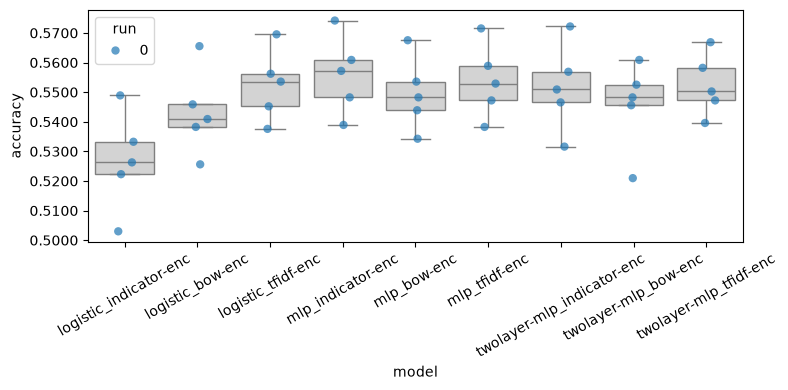

In [27]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

# Bayesian estimation and ROPE

In [28]:
# First, a little helper, to gather all accuracies across runs and folds
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])

# this will have shape [num_runs, num_folds]
get_all_measurements_for(my_classifiers, 'logistic_indicator-enc')

array([[0.53324468, 0.50299401, 0.52628077, 0.52228876, 0.5489022 ]])

In [29]:


ROPE = 0.005 

def compare_all_pairs(classifiers, rope_size=ROPE, runs=1, plot=False):
    rows = []
    for name_a, name_b in combinations(classifiers.keys(), 2):
        posterior = part1.analysis.BenavoliCorrelatedT(
            get_all_measurements_for(classifiers, name_a).flatten(),
            get_all_measurements_for(classifiers, name_b).flatten(),
            runs=runs,
            names=[name_a, name_b],
        )
        p_a, p_tie, p_b = posterior.probs(rope_size)
        rows.append({
            "A": name_a,
            "B": name_b,
            "mean diff (B-A)": posterior.mean_diff,
            "P(A wins)": p_a,
            "P(tie / in ROPE)": p_tie,
            "P(B wins)": p_b,
            "effect size": posterior.effect_size,
        })
        if plot:
            posterior.plot(rope_size)
    return pd.DataFrame(rows)

results_df = compare_all_pairs(my_classifiers, rope_size=ROPE, runs=len(my_seeds))
results_df.style.format({
    "mean diff (B-A)": "{:+.4f}",
    "P(A wins)": "{:.3f}",
    "P(tie / in ROPE)": "{:.3f}",
    "P(B wins)": "{:.3f}",
    "effect size": "{:.2f}",
})


,A,B,mean diff (B-A),P(A wins),P(tie / in ROPE),P(B wins),effect size
0,logistic_indicator-enc,logistic_bow-enc,+0.0165,0.001,0.008,0.991,5.59
1,logistic_indicator-enc,logistic_tfidf-enc,+0.0257,0.004,0.011,0.985,4.14
2,logistic_indicator-enc,mlp_indicator-enc,+0.0291,0.010,0.018,0.972,3.22
3,logistic_indicator-enc,mlp_bow-enc,+0.0228,0.004,0.012,0.984,4.15
4,logistic_indicator-enc,mlp_tfidf-enc,+0.0270,0.003,0.007,0.990,4.64
5,logistic_indicator-enc,twolayer-mlp_indicator-enc,+0.0249,0.002,0.005,0.993,5.28
6,logistic_indicator-enc,twolayer-mlp_bow-enc,+0.0189,0.001,0.006,0.993,5.67
7,logistic_indicator-enc,twolayer-mlp_tfidf-enc,+0.0257,0.004,0.011,0.984,4.03
8,logistic_bow-enc,logistic_tfidf-enc,+0.0092,0.023,0.201,0.776,1.84
9,logistic_bow-enc,mlp_indicator-enc,+0.0126,0.075,0.167,0.758,1.28


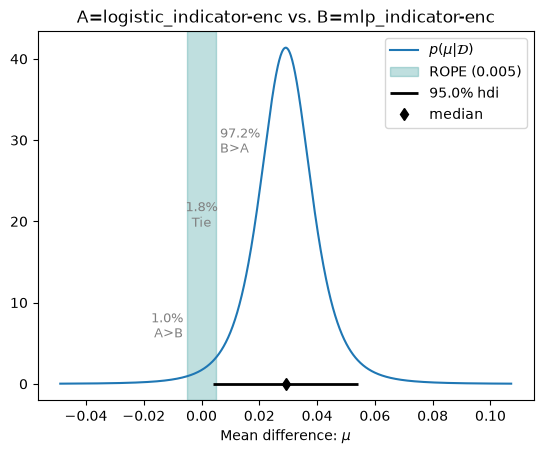

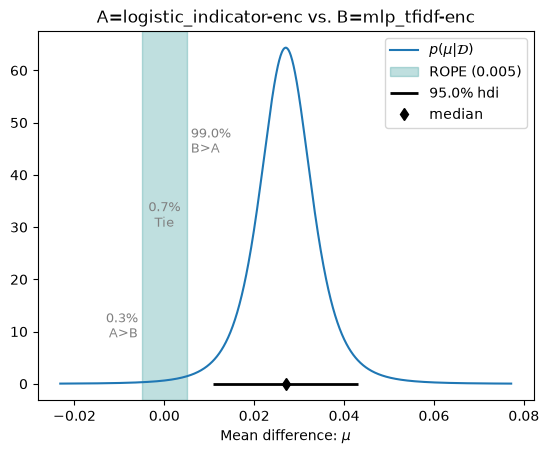

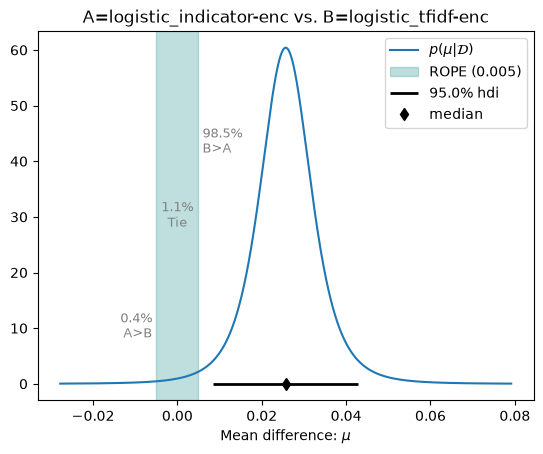

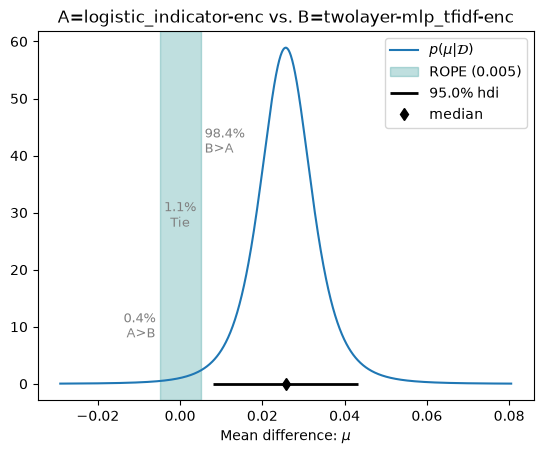

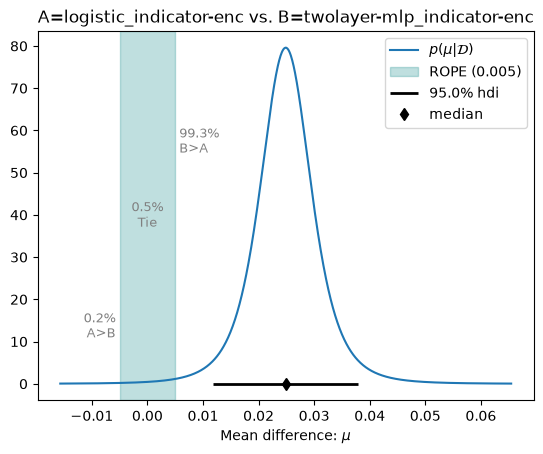

In [ ]:
def plot_pair(name_a, name_b, rope_size=ROPE):
    posterior = part1.analysis.BenavoliCorrelatedT(
        get_all_measurements_for(my_classifiers, name_a).flatten(),
        get_all_measurements_for(my_classifiers, name_b).flatten(),
        runs=len(my_seeds), names=[name_a, name_b],
    )
    return posterior.plot(rope_size)

pairs = []
for a, b in combinations(my_classifiers.keys(), 2):
    diff = get_all_measurements_for(my_classifiers, b).mean() - get_all_measurements_for(my_classifiers, a).mean()
    pairs.append((abs(diff), a, b))

for _, a, b in sorted(pairs, reverse=True)[:5]: # remove 5 to see all plots
    _ = plot_pair(a, b)
